# Heading correction

Three example trajectories, one per flight regime (upwind, crosswind, downwind), showing the measured body orientation before (left) and after (right) the heading-correction steps. Red triangles are the heading; black ellipses are the recorded body ellipses; blue and green arrows are air velocity and thrust.

- **Before:** `pipelinedata/02_augmented/` — measured orientation, accurate only modulo π.
- **After:** `pipelinedata/04_filtered/` — after thrust-referenced correction, spike repair and filtering (before smoothing).

Examples are chosen from trajectories whose heading was substantially changed by the correction.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath('../utils'))
from utils import plot_trajectory, circular_distance

raw = pd.read_csv('../pipelinedata/02_augmented/all_wind_heading_and_trajectories_augmented.csv')
cor = pd.read_csv('../pipelinedata/04_filtered/all_wind_heading_and_trajectories_augmented_corrected_filtered.csv')

## Choosing examples

For every trajectory present in both stages, a frame counts as *corrected* if the correction rotated the heading by more than π/2 (i.e. it resolved a π flip). The trajectory's regime is the regime (upwind $|\theta|\le45^\circ$, downwind within $45^\circ$ of $180^\circ$, otherwise crosswind) in which most of its corrected frames fall. Candidates are ranked by the number of switches between corrected and uncorrected runs, so that the "before" panel visibly flips back and forth. Almost every upwind trajectory is flipped over its whole length, so for upwind the filter is relaxed to partially-corrected trajectories.

In [2]:
m = cor[['trajec_objid', 'timestamp', 'heading_angle', 'windspeed']].merge(
    raw[['trajec_objid', 'timestamp', 'heading_angle']], on=['trajec_objid', 'timestamp'], suffixes=('', '_raw'))
m['flipped'] = np.abs(circular_distance(m['heading_angle'].values, m['heading_angle_raw'].values)) > np.pi / 2

def classify(h):
    deg = np.degrees(np.arctan2(np.sin(h), np.cos(h)))
    return np.where(np.abs(deg) <= 45, 'upwind', np.where(np.abs(np.abs(deg) - 180) <= 45, 'downwind', 'crosswind'))
m['regime'] = classify(m['heading_angle'].values)

rows = []
for tid, g in m.groupby('trajec_objid'):
    f = g['flipped'].values
    rows.append({'trajec_objid': tid, 'n_frames': len(g), 'frac_corrected': f.mean(), 'n_switches': int((f[1:] != f[:-1]).sum()),
                 'windspeed': g['windspeed'].iloc[0], 'regime': g['regime'].value_counts().idxmax()})
stats = pd.DataFrame(rows)

cands = {}
for reg, (lo, hi, nmin) in {'upwind': (0.1, 0.95, 60), 'crosswind': (0.25, 0.75, 80), 'downwind': (0.25, 0.75, 80)}.items():
    s = stats[(stats['regime'] == reg) & stats['n_frames'].between(nmin, 400) & stats['frac_corrected'].between(lo, hi)]
    cands[reg] = s.sort_values('n_switches', ascending=False).head(5)
    print(reg); display(cands[reg].round(2))

upwind


,trajec_objid,n_frames,frac_corrected,n_switches,windspeed,regime
2283,20130401_180544_7307,60,0.70,5,0.3,upwind
1837,20130328_180731_6507,66,0.76,3,0.3,upwind
1233,20130327_193200_14633,69,0.78,1,0.3,upwind


crosswind


,trajec_objid,n_frames,frac_corrected,n_switches,windspeed,regime
402,20121210_201202_5363,149,0.54,20,0.4,crosswind
1736,20130328_180731_15789,214,0.40,17,0.3,crosswind
2279,20130401_180544_7065,88,0.30,15,0.3,crosswind
291,20121210_201202_2578,244,0.50,10,0.4,crosswind
1059,20130325_193727_9696,86,0.34,10,0.4,crosswind


downwind


,trajec_objid,n_frames,frac_corrected,n_switches,windspeed,regime
398,20121210_201202_5295,93,0.39,12,0.4,downwind
722,20130321_182151_6680,177,0.46,11,0.4,downwind
1363,20130327_193200_2800,177,0.38,11,0.3,downwind
1801,20130328_180731_4752,105,0.44,10,0.3,downwind
480,20121210_201202_7646,132,0.29,7,0.4,downwind


The selected example for each regime (the choices below were made from the candidate tables above after viewing them):

In [3]:
EXAMPLES = {
    'upwind':    '20130401_180544_7307',
    'crosswind': '20130328_180731_15789',
    'downwind':  '20130321_182151_6680',
}

def before_after(tid, regime, n_arrows=28):
    b = raw[raw['trajec_objid'] == tid].reset_index(drop=True)
    a = cor[cor['trajec_objid'] == tid].reset_index(drop=True)
    # glyph sizes scale with the trajectory's extent so heading arrows stay legible
    xr = np.ptp(b['position_x']); yr = np.ptp(b['position_y']); extent = max(xr, yr)
    xymean = np.mean(np.abs(np.hstack((b['position_x'], b['position_y']))))
    kw = dict(every_nth=max(2, len(b) // n_arrows), L=0.04 * extent,
              heading_color='red', heading_size=0.09 * extent / (0.21 * xymean),
              arrow_scale=6 * extent, arrow_width=0.006)
    panel_w = 5.5
    panel_h = float(np.clip(panel_w * (yr + 0.02) / (xr + 0.02), 3.5, 8))
    fig, axs = plt.subplots(1, 2, figsize=(2 * panel_w + 0.8, panel_h + 0.9), dpi=150, sharex=True, sharey=True)
    plot_trajectory(axs[0], b, legend=True, **kw)
    plot_trajectory(axs[1], a, legend=False, **kw)
    axs[0].set_title('Before correction (measured, modulo $\\pi$)')
    axs[1].set_title('After correction')
    s = stats.set_index('trajec_objid').loc[tid]
    fig.suptitle(f'{regime.capitalize()} example: {tid} ({int(s.n_frames)} frames, {100 * s.frac_corrected:.0f}% rotated by $\\pi$)')
    fig.tight_layout()
    os.makedirs('../figures', exist_ok=True)
    fig.savefig(f'../figures/heading_correction_{regime}.pdf', bbox_inches='tight')
    fig.savefig(f'../figures/heading_correction_{regime}.png', dpi=300, bbox_inches='tight')
    plt.show()

## Figure 1 — upwind

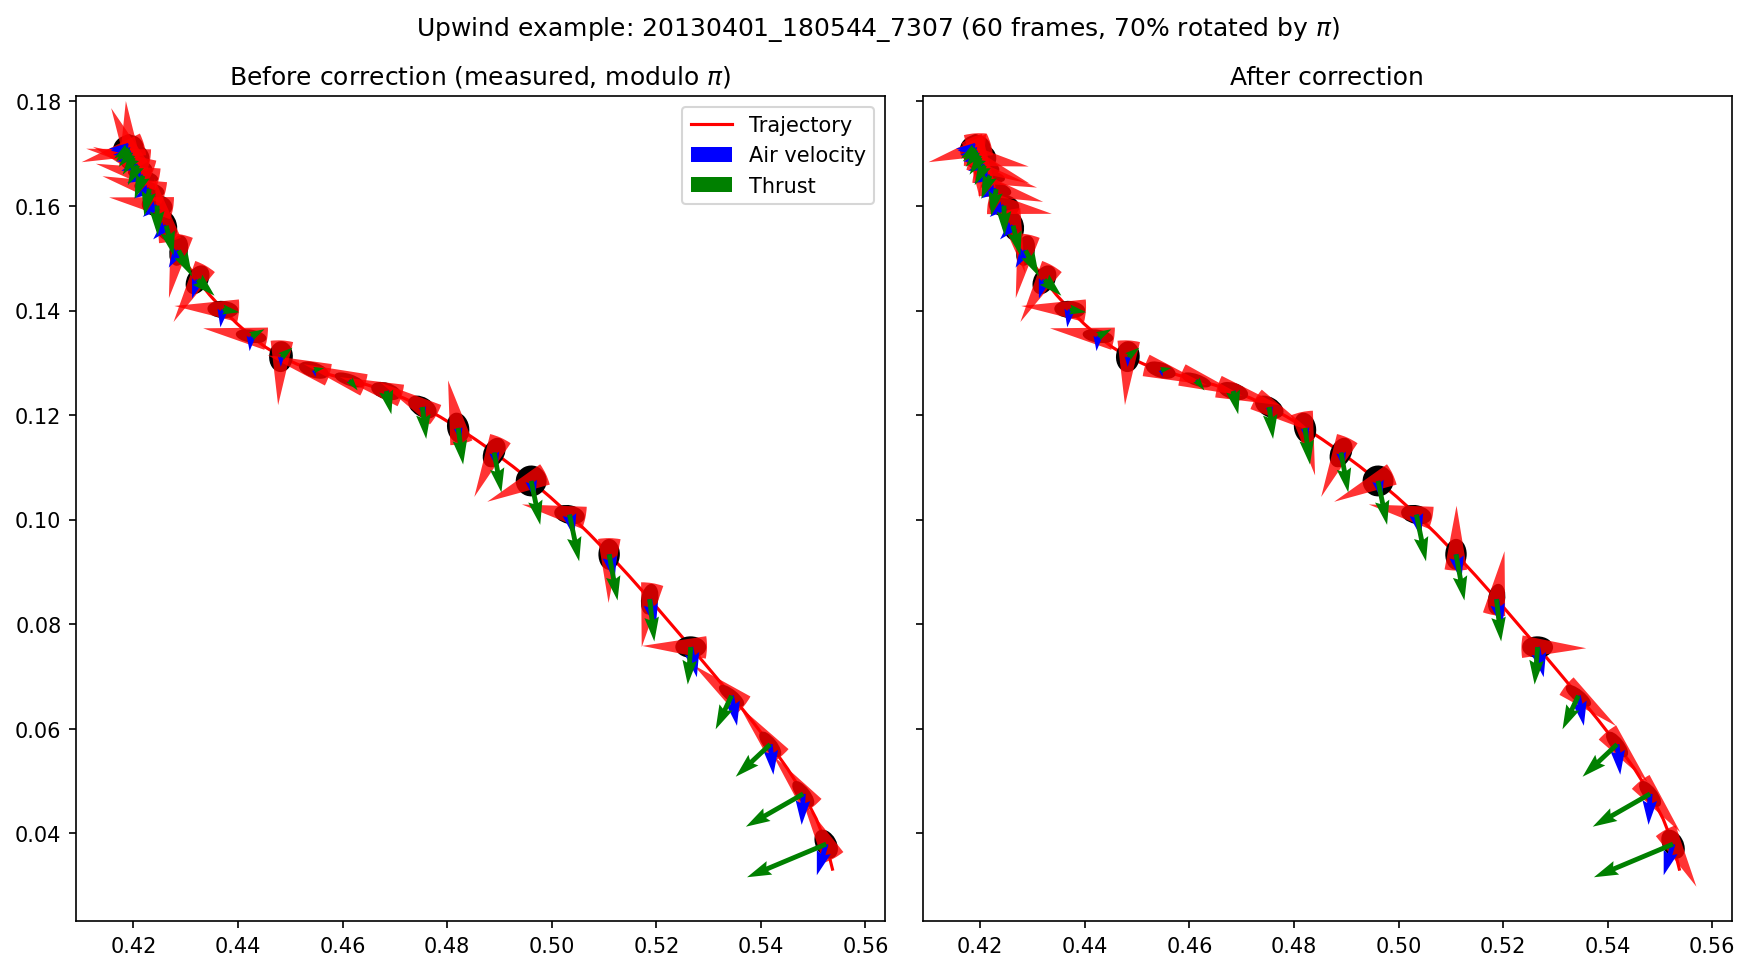

In [4]:
before_after(EXAMPLES['upwind'], 'upwind', n_arrows=30)

## Figure 2 — crosswind

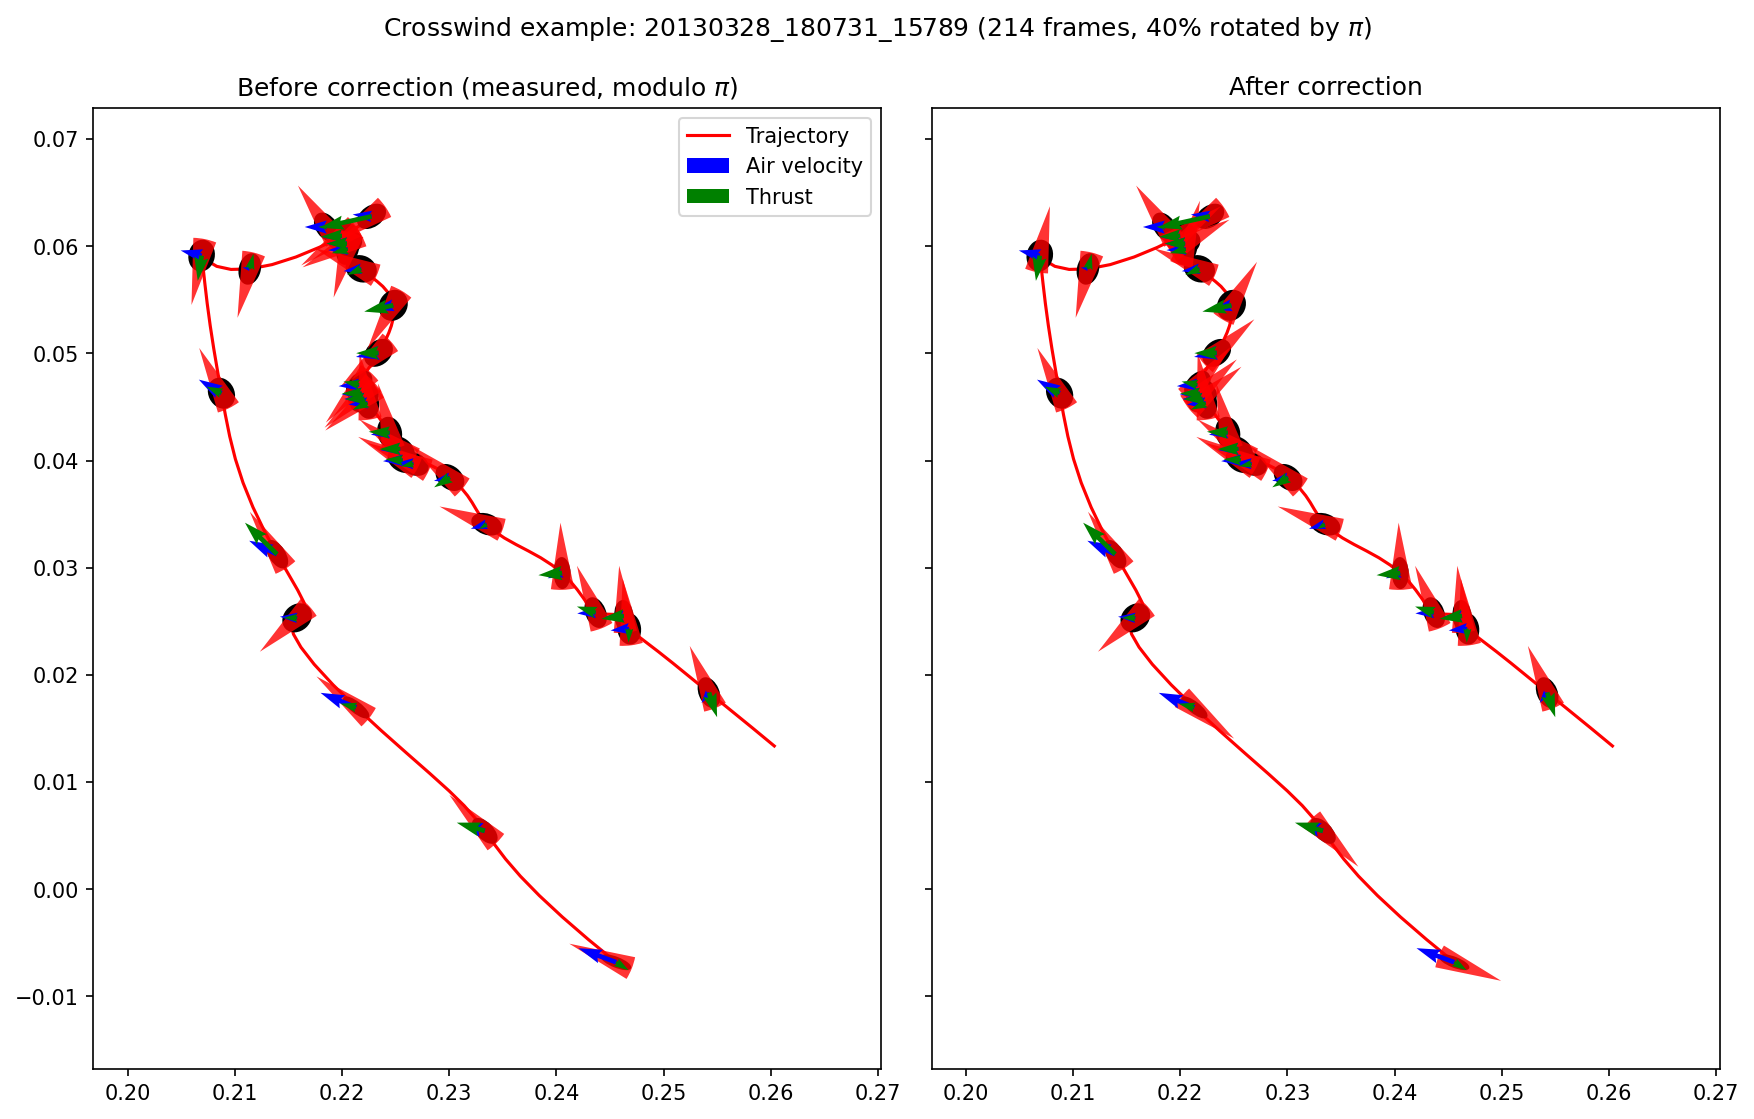

In [5]:
before_after(EXAMPLES['crosswind'], 'crosswind')

## Figure 3 — downwind

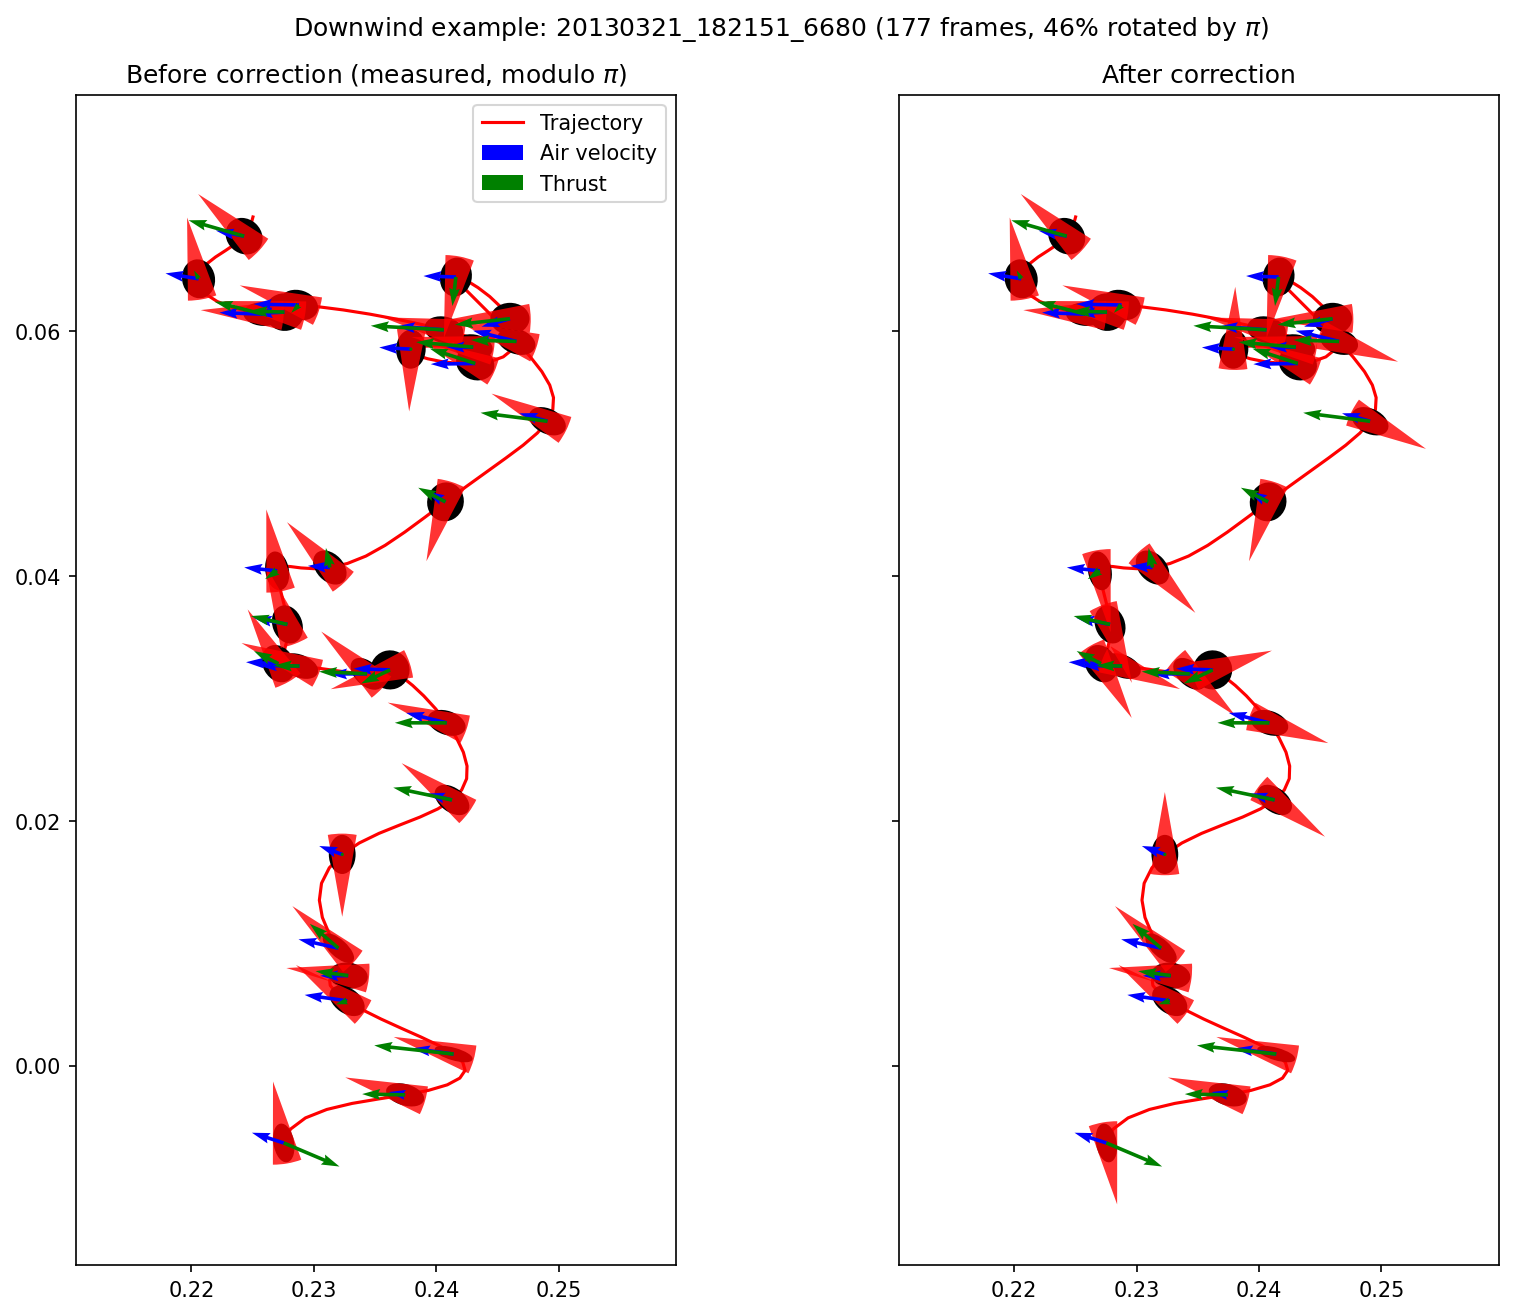

In [6]:
before_after(EXAMPLES['downwind'], 'downwind')